# **Import Some Libraries  :**

In [1]:
import os
from keras.preprocessing import image
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow import keras
from keras.layers import *
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.regularizers import l2
from tensorflow.keras.preprocessing import image
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.applications import ResNet152
from tensorflow.keras import layers, models, regularizers
from tensorflow.keras.callbacks import EarlyStopping
import tensorflow as tf
from tensorflow.keras.applications import EfficientNetB7
from PIL import Image
import warnings
warnings.filterwarnings('ignore')


# **Prepare Some Functions To Be Used :**

## Data Visualization :

In [2]:
def PlotImages(Diseases):
    plt.figure(figsize = (19,19))

    for i, Disease in enumerate(Diseases):
        ImagePath = TrainPath + '/' + Disease
        ImagesInFolder = os.listdir(ImagePath)

        STImage = ImagesInFolder[0]
        STImagePath = ImagePath + '/' + STImage

        Image = image.load_img(STImagePath)
        ImagesArray = image.img_to_array(Image) / 255

        plt.subplot(1,7, i+1)
        plt.imshow(ImagesArray)
        plt.title(Disease)
        plt.axis('off')
    plt.show()

## Make a Prediction :

In [3]:
# Define ImageDataGenerator with preprocessing
ImageGen = ImageDataGenerator(
    rescale=1./255,
    zoom_range=0.2,
    brightness_range=[0.8, 1.2],  # Vary brightness (simulates noise-like variation)
    width_shift_range=0.1,  # Small horizontal shifts to introduce randomness
    height_shift_range=0.1,  # Small vertical shifts
    rotation_range=10,  # Slight rotation for distortion
    shear_range=0.1  # Shear transformation
)


def prediction(testing_image, actual_label):
    # Load and preprocess the image
    test_img = image.load_img(testing_image, target_size=(224, 224))
    test_img_array = image.img_to_array(test_img)
    
    # Apply ImageDataGenerator transformations
    test_img_array = ImageGen.random_transform(test_img_array)  # Apply zoom augmentation
    test_img_array /= 255.0  # Ensure rescaling

    test_img_input = np.expand_dims(test_img_array, axis=0)  # Reshape for model input

    # Make prediction
    predicted_class = np.argmax(BuiltInEfficientNet_Modified.predict(test_img_input))
    class_img = class_map[predicted_class]

    # Display the image with prediction
    plt.figure(figsize=(4, 4))
    plt.imshow(test_img_array)
    plt.title("Actual Label: {} , Predicted Label: {}".format(actual_label, class_img))
    plt.grid(False)
    plt.axis('off')
    plt.show()


## Plot the Augmented images :

In [4]:
def plot_augmentation(img_path):
    img_gen = ImageDataGenerator(
        zoom_range=0.2,
        brightness_range=[0.8, 1.2],
        width_shift_range=0.1,
        height_shift_range=0.1,
        rotation_range=10,
    )
    
    # Load and preprocess the image
    img = image.load_img(img_path, target_size=(224, 224))
    img_array = image.img_to_array(img)  # Remove manual normalization
    img_array = np.expand_dims(img_array, axis=0)  # Add batch dimension
    
    # Generate augmented image
    augmented_img = next(img_gen.flow(img_array, batch_size=1))[0].astype("uint8")  # Convert back to uint8
    
    # Plot original and augmented images
    fig, ax = plt.subplots(1, 2, figsize=(8, 4))
    ax[0].imshow(img_array[0].astype("uint8"))  # Convert for display
    ax[0].set_title("Original Image")
    ax[0].axis("off")
    
    ax[1].imshow(augmented_img)
    ax[1].set_title("Augmented Image")
    ax[1].axis("off")
    
    plt.show()


# **Reading The Dataset :**

In [5]:
TrainPath = '/kaggle/input/oral-diseases-dataset-7-different-diseases/Oral Diseases Dataset/Training'
TestPath = '/kaggle/input/oral-diseases-dataset-7-different-diseases/Oral Diseases Dataset/Testing'
ValidationPath='/kaggle/input/oral-diseases-dataset-7-different-diseases/Oral Diseases Dataset/Validation'


# **Exploring All Diseases With Example for Each One :**

In [6]:
Diseases = os.listdir('/kaggle/input/oral-diseases-dataset-7-different-diseases/Oral Diseases Dataset/Training')
Diseases

['OC', 'CaS', 'OT', 'CoS', 'Gum', 'MC', 'OLP']

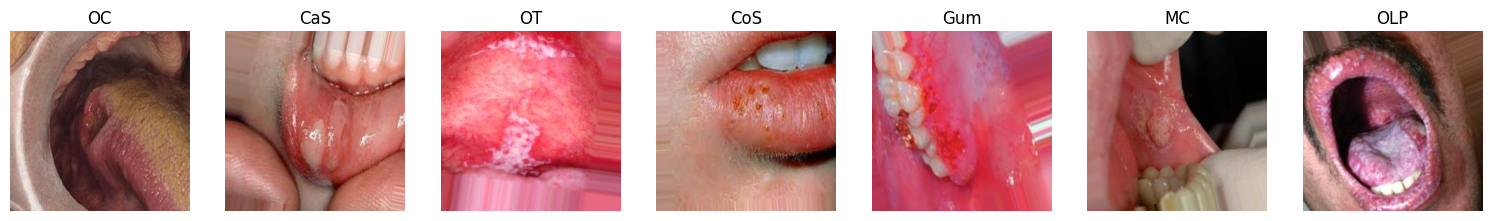

In [7]:
PlotImages(Diseases)

# **Image Preprocessing :**

In [8]:
ImageGen = ImageDataGenerator(
    rescale=1./255,
    zoom_range=0.2,
    brightness_range=[0.8, 1.2],  # Vary brightness (simulates noise-like variation)
    width_shift_range=0.1,  # Small horizontal shifts to introduce randomness
    height_shift_range=0.1,  # Small vertical shifts
    rotation_range=10,  # Slight rotation for distortion
    shear_range=0.1  # Shear transformation
)


In [9]:
TrainSet = ImageGen.flow_from_directory(TrainPath,target_size = (224,224),class_mode='categorical')

Found 3087 images belonging to 7 classes.


In [10]:
TestSet = ImageGen.flow_from_directory(TestPath, target_size=(224,224), class_mode='categorical', batch_size=32)


Found 1028 images belonging to 7 classes.


In [11]:
ValidationSet = ImageGen.flow_from_directory(ValidationPath,target_size = (224,224),class_mode='categorical')

Found 1028 images belonging to 7 classes.


# **Plotting The Difference Between After And Before Augmentation :**

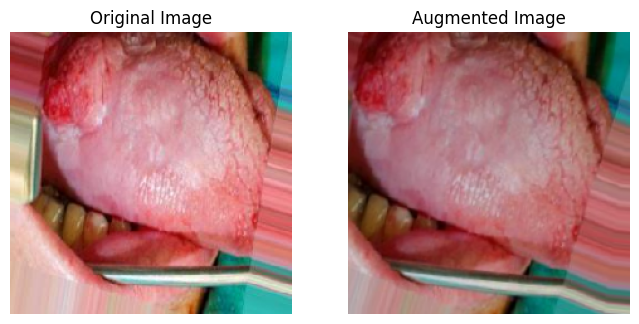

In [12]:
plot_augmentation('/kaggle/input/oral-diseases-dataset-7-different-diseases/Oral Diseases Dataset/Training/OC/oc_1200_0_416.jpg')

# **Model Building :**

**There were many trials before this many but this was the best one by the highest validation score and least overfitting percentage**

In [13]:
# Load Pretrained EfficientNet-B7 Model (without top layers)
base_model = EfficientNetB7(weights="imagenet", include_top=False, input_shape=(224, 224, 3))

# Fine-tune the model by unfreezing some layers
base_model.trainable = True
fine_tune_at = 200  # Fine-tune from layer 200 onwards
for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

# Build the new model on top of EfficientNet-B7
BuiltInEfficientNet_Modified = models.Sequential([
    base_model,
    
    # Flatten layer instead of GlobalAveragePooling2D for better dense layer performance
    layers.Flatten(),
    
    # Dense layers with L2 regularization to prevent overfitting
    layers.Dense(512, activation='relu', kernel_regularizer=regularizers.l2(0.00001)),
    layers.BatchNormalization(),

    layers.Dense(256, activation='relu', kernel_regularizer=regularizers.l2(0.01)),
    layers.BatchNormalization(),

    layers.Dense(128, activation='relu'),
    layers.BatchNormalization(),

    layers.Dense(128, activation='relu'),
    layers.BatchNormalization(),

    layers.Dense(64, activation='relu'),
    layers.Dropout(0.3),

    layers.Dense(7, activation='softmax')  # 7 classes
])


258076736/258076736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


# **Compile & Fit Model :**

In [14]:
# Compile the model
BuiltInEfficientNet_Modified.compile(optimizer='adamax', loss='categorical_crossentropy', metrics=['accuracy'])

In [15]:
early_stop = EarlyStopping(monitor='val_loss', patience=13, restore_best_weights=True)

In [16]:
BuiltInEfficientNet_Modifiedt_History = BuiltInEfficientNet_Modified.fit(TrainSet, epochs=100, validation_data=ValidationSet, callbacks=[early_stop])

Epoch 1/100
97/97 ━━━━━━━━━━━━━━━━━━━━ 383s 2s/step - accuracy: 0.1546 - loss: 5.5956 - val_accuracy: 0.1751 - val_loss: 5.2135
Epoch 2/100
97/97 ━━━━━━━━━━━━━━━━━━━━ 63s 614ms/step - accuracy: 0.1965 - loss: 5.0709 - val_accuracy: 0.1780 - val_loss: 4.7771
Epoch 3/100
97/97 ━━━━━━━━━━━━━━━━━━━━ 62s 611ms/step - accuracy: 0.2225 - loss: 4.7150 - val_accuracy: 0.1420 - val_loss: 4.5751
Epoch 4/100
97/97 ━━━━━━━━━━━━━━━━━━━━ 62s 609ms/step - accuracy: 0.2443 - loss: 4.4125 - val_accuracy: 0.2860 - val_loss: 4.1431
Epoch 5/100
97/97 ━━━━━━━━━━━━━━━━━━━━ 62s 613ms/step - accuracy: 0.2662 - loss: 4.0984 - val_accuracy: 0.3648 - val_loss: 3.7325
Epoch 6/100
97/97 ━━━━━━━━━━━━━━━━━━━━ 62s 612ms/step - accuracy: 0.3141 - loss: 3.7986 - val_accuracy: 0.4173 - val_loss: 3.4380
Epoch 7/100
97/97 ━━━━━━━━━━━━━━━━━━━━ 62s 610ms/step - accuracy: 0.3452 - loss: 3.5104 - val_accuracy: 0.4163 - val_loss: 3.1477
Epoch 8/100
97/97 ━━━━━━━━━━━━━━━━━━━━ 62s 608ms/step - accuracy: 0.3780 - loss: 3.1947 - va

In [17]:
# Print model summary
BuiltInEfficientNet_Modified.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ efficientnetb7 (Functional)          │ (None, 7, 7, 2560)          │      64,097,687 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 125440)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 512)                 │      64,225,792 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 512)                 │           2,048 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 256)                 │         131,328 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 256)                 │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 128)                 │          32,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_2                │ (None, 128)                 │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 128)                 │          16,512 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_3                │ (None, 128)                 │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 7)                   │             455 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 383,845,622 (1.43 GB)

 Trainable params: 127,664,299 (487.00 MB)

 Non-trainable params: 852,723 (3.25 MB)

 Optimizer params: 255,328,600 (974.00 MB)

# **Model Performance Visualization :**

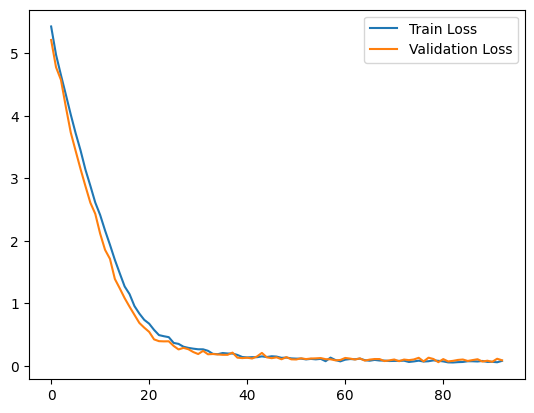

In [18]:
plt.plot(BuiltInEfficientNet_Modifiedt_History.history['loss'], label = 'Train Loss')
plt.plot(BuiltInEfficientNet_Modifiedt_History.history['val_loss'], label = 'Validation Loss')
plt.legend()
plt.show()

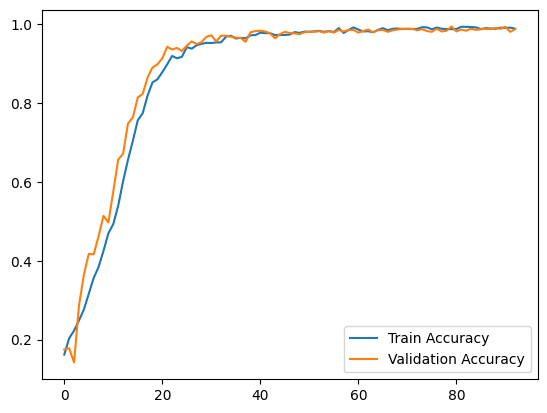

In [19]:
plt.plot(BuiltInEfficientNet_Modifiedt_History.history['accuracy'], label = 'Train Accuracy')
plt.plot(BuiltInEfficientNet_Modifiedt_History.history['val_accuracy'], label = 'Validation Accuracy')
plt.legend()
plt.show()

# **Model Evaluation :**

In [20]:
BuiltInEfficientNet_Modified.evaluate(TrainSet)

97/97 ━━━━━━━━━━━━━━━━━━━━ 45s 467ms/step - accuracy: 0.9971 - loss: 0.0365


[0.03475864976644516, 0.9983803033828735]

In [21]:
BuiltInEfficientNet_Modified.evaluate(TestSet)

33/33 ━━━━━━━━━━━━━━━━━━━━ 19s 585ms/step - accuracy: 0.9918 - loss: 0.0531


[0.06172515079379082, 0.9892995953559875]

# **Prininting The Final Weights :**

In [22]:
for layer in BuiltInEfficientNet_Modified.layers:
    print(f"Layer: {layer.name}")
    print(layer.get_weights())  # Prints weights for each layer
    print("\n")


Layer: efficientnetb7
[array([0.485, 0.456, 0.406], dtype=float32), array([0.229, 0.224, 0.225], dtype=float32), 0, array([[[[-3.77828836e-01,  2.76361465e-01, -8.32918435e-02, ...,
          -1.77597940e-01,  1.47596002e-05,  1.39584079e-01],
         [-6.60683036e-01,  1.39902234e+00, -3.56699824e-02, ...,
          -1.40343934e-01, -5.77094033e-06,  6.66381001e-01],
         [-3.44433308e-01,  1.52912617e-01, -8.17556828e-02, ...,
          -1.24101147e-01, -2.71759927e-05,  5.86694404e-02]],

        [[-4.45116431e-01,  6.77551866e-01, -2.87770331e-02, ...,
          -1.19002983e-01,  1.84602104e-05,  2.16148943e-01],
         [-5.31597972e-01,  2.03446937e+00,  7.67395571e-02, ...,
          -2.53242254e-01, -5.64008951e-06,  8.14347565e-01],
         [-3.81152987e-01,  3.05624515e-01, -7.36741908e-03, ...,
          -3.01417522e-02, -3.34978104e-05,  1.09322563e-01]],

        [[-1.06738612e-01, -5.20270038e-03,  1.03740282e-02, ...,
           8.16780329e-02,  1.25374645e-05,  7

# **Printing The Expected Shapes for Inputs & Outputs :**

In [23]:
print(BuiltInEfficientNet_Modified.input_shape)


(None, 224, 224, 3)


In [24]:
print(BuiltInEfficientNet_Modified.output_shape)


(None, 7)


In [25]:
for images, labels in TestSet:
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    break


Image batch shape: (32, 224, 224, 3)
Label batch shape: (32, 7)


# **Make Predictions For Each Class :**

In [26]:
class_map = dict([value, key] for key, value in TrainSet.class_indices.items())
class_map

{0: 'CaS', 1: 'CoS', 2: 'Gum', 3: 'MC', 4: 'OC', 5: 'OLP', 6: 'OT'}

1/1 ━━━━━━━━━━━━━━━━━━━━ 15s 15s/step


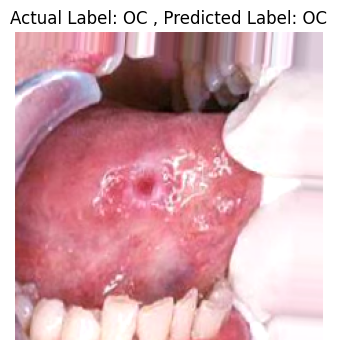

In [27]:
testing_image = '/kaggle/input/oral-diseases-dataset-7-different-diseases/Oral Diseases Dataset/Testing/OC/oc_1213.jpg'
prediction(testing_image, actual_label = 'OC')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step


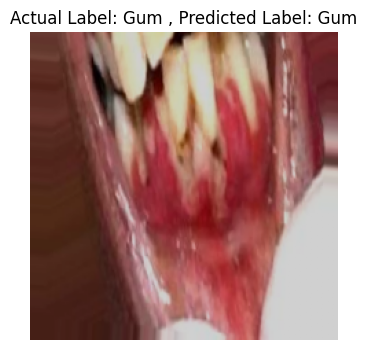

In [28]:
testing_image = '/kaggle/input/oral-diseases-dataset-7-different-diseases/Oral Diseases Dataset/Testing/Gum/g_1206_0_5439.jpg'
prediction(testing_image, actual_label = 'Gum')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step


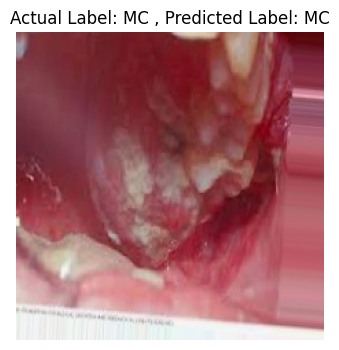

In [29]:
testing_image = '/kaggle/input/oral-diseases-dataset-7-different-diseases/Oral Diseases Dataset/Testing/MC/mc_1201.jpg'
prediction(testing_image, actual_label = 'MC')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step


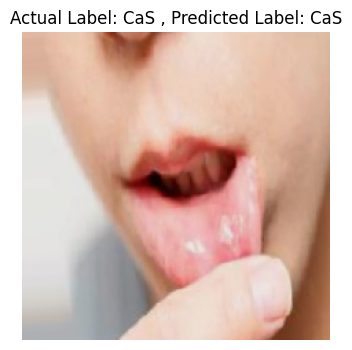

In [30]:
testing_image = '/kaggle/input/oral-diseases-dataset-7-different-diseases/Oral Diseases Dataset/Training/CaS/a_100_0_6639.jpg'
prediction(testing_image, actual_label = 'CaS')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step


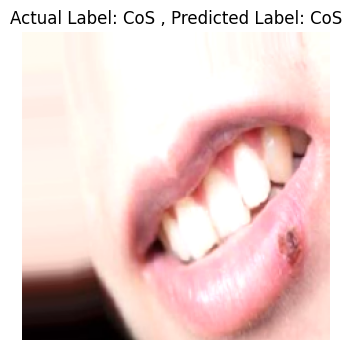

In [31]:
testing_image = '/kaggle/input/oral-diseases-dataset-7-different-diseases/Oral Diseases Dataset/Training/CoS/b_100_0_6694.jpg'
prediction(testing_image, actual_label = 'CoS')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step


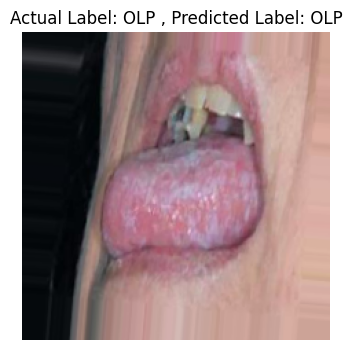

In [32]:
testing_image = '/kaggle/input/oral-diseases-dataset-7-different-diseases/Oral Diseases Dataset/Training/OLP/p_1200_0_7326.jpg'
prediction(testing_image, actual_label = 'OLP')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step


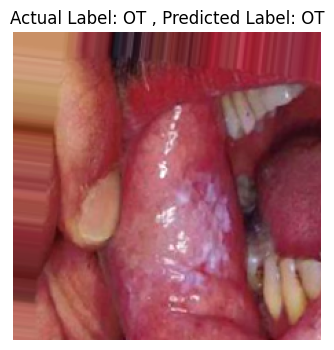

In [33]:
testing_image = '/kaggle/input/oral-diseases-dataset-7-different-diseases/Oral Diseases Dataset/Training/OT/ot_1200_0_3131.jpg'
prediction(testing_image, actual_label = 'OT')

# **Deploying The Final Model :**

In [34]:
# Save as a Python file and intall streamlit library, then run this command :  streamlit run app.py  (in Anaconda Prompt) in the same directory of the deployment app.
# The Deployment UI Code:

'''
import streamlit as st
import tensorflow as tf
import numpy as np
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from PIL import Image

# Apply Custom CSS for Styling
st.markdown(
    """
    <style>
    body {
        background-color: #f4f4f9 !important;
    }
    .stApp {
        color: #333333;
        font-family: Arial, sans-serif;
    }
    .prediction-text, .explanation-text {
        font-size: 26px !important;
        font-weight: bold;
        color: #DBE0E7; /* Light Grayish Blue */
        text-align: center;
    }
    .upload-message {
        font-size: 28px !important;
        font-weight: bold;
        color: #B0C4DE; /* Light Steel Blue */
        text-align: center;
    }
    .title-text {
        font-size: 30px !important;
        font-weight: bold;
        color: #B0C4DE; /* Light Steel Blue */
        text-align: center;
    }
    .subtitle-text {
        font-size: 26px !important;
        font-weight: bold;
        color: #B0C4DE; /* Light Steel Blue */
        text-align: center;
    }
    .loading-message {
        font-size: 18px !important;
        font-weight: bold;
        color: #E7E7EC; /* Light Gray */
        text-align: center;
        margin-top: -10px;
    }
    .centered-container {
        display: flex;
        justify-content: center;
        align-items: center;
    }
    </style>
    """,
    unsafe_allow_html=True
)

@st.cache_resource
def load_model():
    return tf.keras.models.load_model("/kaggle/input/final-model/tensorflow1/last-version/1/Oral Diseases Classification EfficentNetB7 Model with 98 Accuracy.h5")

model = load_model()

# Define Image Augmentation for Inference
ImageGen = ImageDataGenerator(
    rescale=1./255,
    zoom_range=0.2,
    brightness_range=[0.8, 1.2],
    width_shift_range=0.1,
    height_shift_range=0.1,
    rotation_range=10,
    shear_range=0.1
)

st.markdown('<p class="title-text">EfficientNetB7 Oral Disease Classifier</p>', unsafe_allow_html=True)
st.markdown('<p class="upload-message">Upload an image for the diagnosis: </p>', unsafe_allow_html=True)

# Display the prediction time message (smaller font size)
st.markdown('<p class="loading-message">The prediction process takes approximately 7 to 25 seconds. Please wait...</p>', unsafe_allow_html=True)

uploaded_file = st.file_uploader("", type=["jpg", "png", "jpeg"], help="Upload an image of an oral disease")

if uploaded_file is not None:
    image = Image.open(uploaded_file)

    # Use a flexbox to center the image
    st.markdown('<div class="centered-container">', unsafe_allow_html=True)
    st.image(image, caption="Uploaded Image", use_column_width=False, width=300)
    st.markdown('</div>', unsafe_allow_html=True)

    img_array = np.array(image)
    img_array = np.expand_dims(img_array, axis=0)  

    img_augmented = next(ImageGen.flow(img_array, batch_size=1, shuffle=False))
    img_augmented = tf.image.resize(img_augmented, (224, 224))

    prediction = model.predict(img_augmented)
    class_label = np.argmax(prediction)
    confidence = np.max(prediction) * 100

    classes = [
        "Candidiasis (CaS)",
        "Cold Sores (CoS)",
        "Gum Disease (GUM)",
        "Mouth Cancer (MC)",
        "Oral Cancer (OC)",
        "Oral Lichen Planus (OLP)",
        "Oral Thrush (OT)"
    ]  
    explanations = {
        "Candidiasis (CaS)": "A fungal infection in the mouth causing white patches. Seek antifungal treatment. And you should visit your dentist first before taking any action. Wishing you a speedy recovery.",
        "Cold Sores (CoS)": "Blisters caused by the herpes simplex virus. Use antiviral creams. But you should visit your dentist first before taking any action. Wishing you a speedy recovery.",
        "Gum Disease (GUM)": "Inflammation leading to gum recession. Improve oral hygiene and visit a dentist. And you should ask your dentist first before taking any action before visiting him. Wishing you a speedy recovery.",
        "Mouth Cancer (MC)": "Serious condition needing immediate medical consultation. And you should visit your dentist first before taking any action. Wishing you a speedy recovery.",
        "Oral Cancer (OC)": "Potentially life-threatening. See a specialist immediately. And you should ask your dentist first before taking any action. Wishing you a speedy recovery.",
        "Oral Lichen Planus (OLP)": "Chronic inflammation needing corticosteroid treatment. And you should visit your dentist first before taking any action. Wishing you a speedy recovery.",
        "Oral Thrush (OT)": "Fungal infection causing white patches. Use antifungal medication. But you should visit your dentist first before taking any action. Wishing you a speedy recovery."
    }
    predicted_class = classes[class_label]
    explanation = explanations[predicted_class]

    st.markdown(f'<p class="prediction-text">Predicted Disease: {predicted_class}</p>', unsafe_allow_html=True)
    st.markdown(f'<p class="prediction-text">Confidence: {confidence:.2f}%</p>', unsafe_allow_html=True)
    st.markdown(f'<p class="explanation-text">{explanation}</p>', unsafe_allow_html=True)

'''


'\nimport streamlit as st\nimport tensorflow as tf\nimport numpy as np\nfrom tensorflow.keras.preprocessing.image import ImageDataGenerator\nfrom PIL import Image\n\n# Apply Custom CSS for Styling\nst.markdown(\n    """\n    <style>\n    body {\n        background-color: #f4f4f9 !important;\n    }\n    .stApp {\n        color: #333333;\n        font-family: Arial, sans-serif;\n    }\n    .prediction-text, .explanation-text {\n        font-size: 26px !important;\n        font-weight: bold;\n        color: #DBE0E7; /* Light Grayish Blue */\n        text-align: center;\n    }\n    .upload-message {\n        font-size: 28px !important;\n        font-weight: bold;\n        color: #B0C4DE; /* Light Steel Blue */\n        text-align: center;\n    }\n    .title-text {\n        font-size: 30px !important;\n        font-weight: bold;\n        color: #B0C4DE; /* Light Steel Blue */\n        text-align: center;\n    }\n    .subtitle-text {\n        font-size: 26px !important;\n        font-weight:

# **Saving The Final Model :**

In [35]:
BuiltInEfficientNet_Modified.save("Oral Diseases Classification EfficientNetB7 Model with 98% Accuracy [OC, CaS, OT, CoS, Gum, MC, OLP].h5")